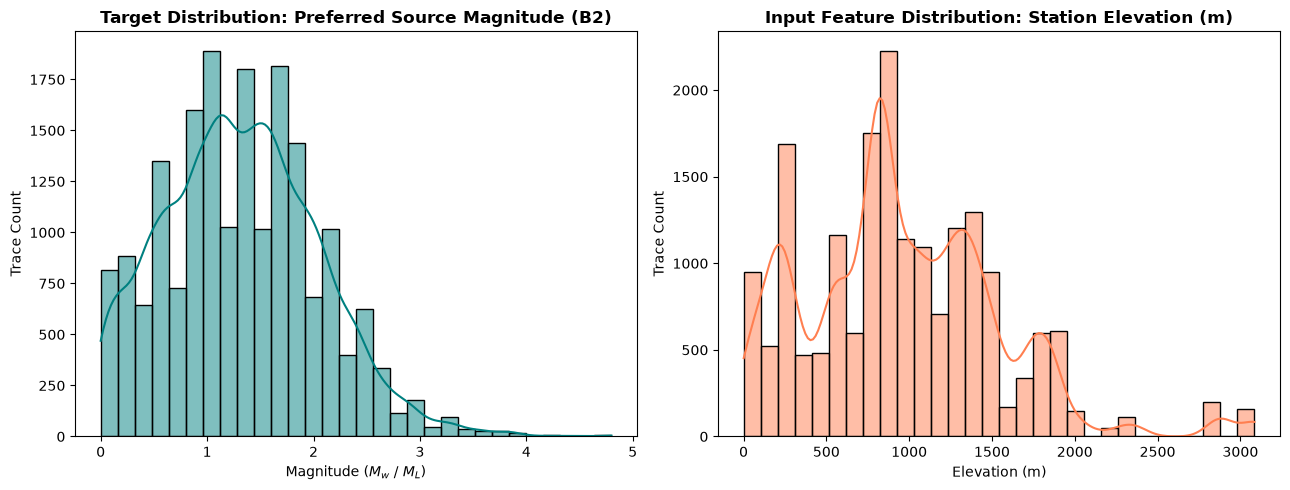

--- B2 DISTRIBUTION EVIDENCE ---
Total Dataset Records: 18640
Rare Tail Events (Magnitude >= 3.0): 329 records (1.77%)


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Setup paths
repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
clean_meta_path = os.path.join(repo_root, "data", "clean", "metadata_clean.parquet")

df = pd.read_parquet(clean_meta_path)

# Set figure style
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Target Magnitude Distribution
sns.histplot(df["preferred_source_magnitude"], kde=True, ax=axes[0], color="teal", bins=30)
axes[0].set_title("Target Distribution: Preferred Source Magnitude (B2)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Magnitude ($M_w$ / $M_L$)")
axes[0].set_ylabel("Trace Count")

# Plot 2: Key Spatial Input Distribution (Station Elevation)
if "station_elevation_m" in df.columns:
    sns.histplot(df["station_elevation_m"], kde=True, ax=axes[1], color="coral", bins=30)
    axes[1].set_title("Input Feature Distribution: Station Elevation (m)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Elevation (m)")
    axes[1].set_ylabel("Trace Count")

plt.tight_layout()
plt.show()

# B2 Rare Tail Analysis
rare_tail_count = (df["preferred_source_magnitude"] >= 3.0).sum()
total_count = len(df)
print("--- B2 DISTRIBUTION EVIDENCE ---")
print(f"Total Dataset Records: {total_count}")
print(f"Rare Tail Events (Magnitude >= 3.0): {rare_tail_count} records ({rare_tail_count/total_count*100:.2f}%)")